In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nelgiriyewithana/top-spotify-songs-2023")

print("Path to dataset files:", path)

Path to dataset files: /home/codespace/.cache/kagglehub/datasets/nelgiriyewithana/top-spotify-songs-2023/versions/1


In [3]:
df = pd.read_csv(f'/home/codespace/.cache/kagglehub/datasets/nelgiriyewithana/top-spotify-songs-2023/versions/1/spotify-2023.csv', encoding='latin-1')
df.shape
df.head

<bound method NDFrame.head of                               track_name      artist(s)_name  artist_count  \
0    Seven (feat. Latto) (Explicit Ver.)    Latto, Jung Kook             2   
1                                   LALA         Myke Towers             1   
2                                vampire      Olivia Rodrigo             1   
3                           Cruel Summer        Taylor Swift             1   
4                         WHERE SHE GOES           Bad Bunny             1   
..                                   ...                 ...           ...   
948                         My Mind & Me        Selena Gomez             1   
949            Bigger Than The Whole Sky        Taylor Swift             1   
950                 A Veces (feat. Feid)  Feid, Paulo Londra             2   
951                        En La De Ella  Feid, Sech, Jhayco             3   
952                                Alone           Burna Boy             1   

     released_year  released_mont

In [4]:
df.columns = (
    df.columns.str.lower()
    .str.replace('_%', '', regex=False)
    .str.replace('(s)', '', regex=False)
)
df.columns.tolist()

['track_name',
 'artist_name',
 'artist_count',
 'released_year',
 'released_month',
 'released_day',
 'in_spotify_playlists',
 'in_spotify_charts',
 'streams',
 'in_apple_playlists',
 'in_apple_charts',
 'in_deezer_playlists',
 'in_deezer_charts',
 'in_shazam_charts',
 'bpm',
 'key',
 'mode',
 'danceability',
 'valence',
 'energy',
 'acousticness',
 'instrumentalness',
 'liveness',
 'speechiness']

In [8]:
df['streams'] = pd.to_numeric(df['streams'], errors='coerce')
df = df.dropna(subset=['streams']).reset_index(drop=True)
df['streams'] = df['streams'].astype(int)

df['key'] = df['key'].fillna('Unknown')

df = df.drop_duplicates(subset=['track_name', 'artist_name']).reset_index(drop=True)

In [9]:
streams_all = df['streams'].copy() # might not use this

threshold = df['streams'].quantile(0.75)
df['mega_hit'] = (df['streams'] >= threshold).astype(int)

In [10]:
audio = ['bpm', 'danceability', 'valence', 'energy', 'acousticness', 'instrumentalness', 'liveness', 'speechiness']
numerical = audio + ['artist_count', 'released_year', 'released_day']
categorical = ['key', 'mode', 'released_month']

df = df[['track_name', 'artist_name'] + numerical + categorical + ['mega_hit']]
df.shape

(948, 17)

In [11]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['mega_hit'].values
y_val = df_val['mega_hit'].values
y_test = df_test['mega_hit'].values

del df_train['mega_hit']
del df_val['mega_hit']
del df_test['mega_hit']

len(df_train), len(df_val), len(df_test), y_train.mean(), y_val.mean(), y_test.mean()

(568,
 190,
 190,
 np.float64(0.25704225352112675),
 np.float64(0.22105263157894736),
 np.float64(0.2578947368421053))

# EDA

In [12]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train.shape

(758, 17)

In [13]:
df_full_train[numerical].describe().round(1)

,bpm,danceability,valence,energy,acousticness,instrumentalness,liveness,speechiness,artist_count,released_year,released_day
count,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0,758.0
mean,122.0,67.0,51.9,64.5,26.7,1.5,18.0,10.1,1.6,2018.2,13.9
std,27.7,14.8,23.8,16.8,25.8,8.2,13.2,10.0,0.9,11.1,9.1
min,65.0,23.0,4.0,14.0,0.0,0.0,3.0,2.0,1.0,1930.0,1.0
25%,100.0,57.0,32.2,53.2,5.0,0.0,10.0,4.0,1.0,2020.0,6.0
50%,120.0,70.0,52.0,66.0,18.0,0.0,12.0,6.0,1.0,2022.0,13.0
75%,140.0,79.0,71.0,77.8,41.0,0.0,23.0,11.0,2.0,2022.0,21.0
max,206.0,96.0,97.0,97.0,97.0,90.0,92.0,64.0,7.0,2023.0,31.0


In [14]:
df_full_train[categorical].nunique()

key               12
mode               2
released_month    12
dtype: int64

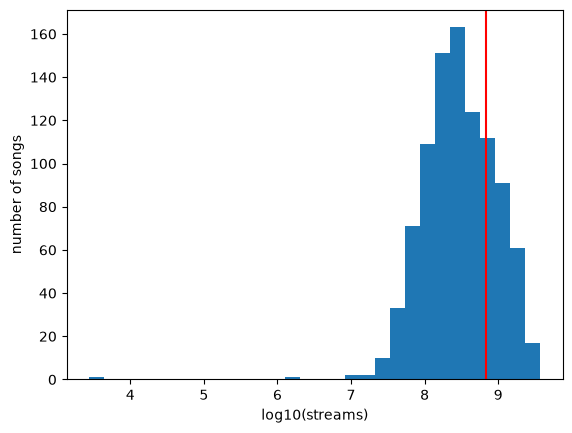

np.float64(0.24802110817941952)

In [21]:
global_rate = df_full_train['mega_hit'].mean()

plt.hist(np.log10(streams_all), bins=30)
plt.axvline(np.log10(threshold), color='red')
plt.xlabel('log10(streams)')
plt.ylabel('number of songs')
plt.show()
global_rate

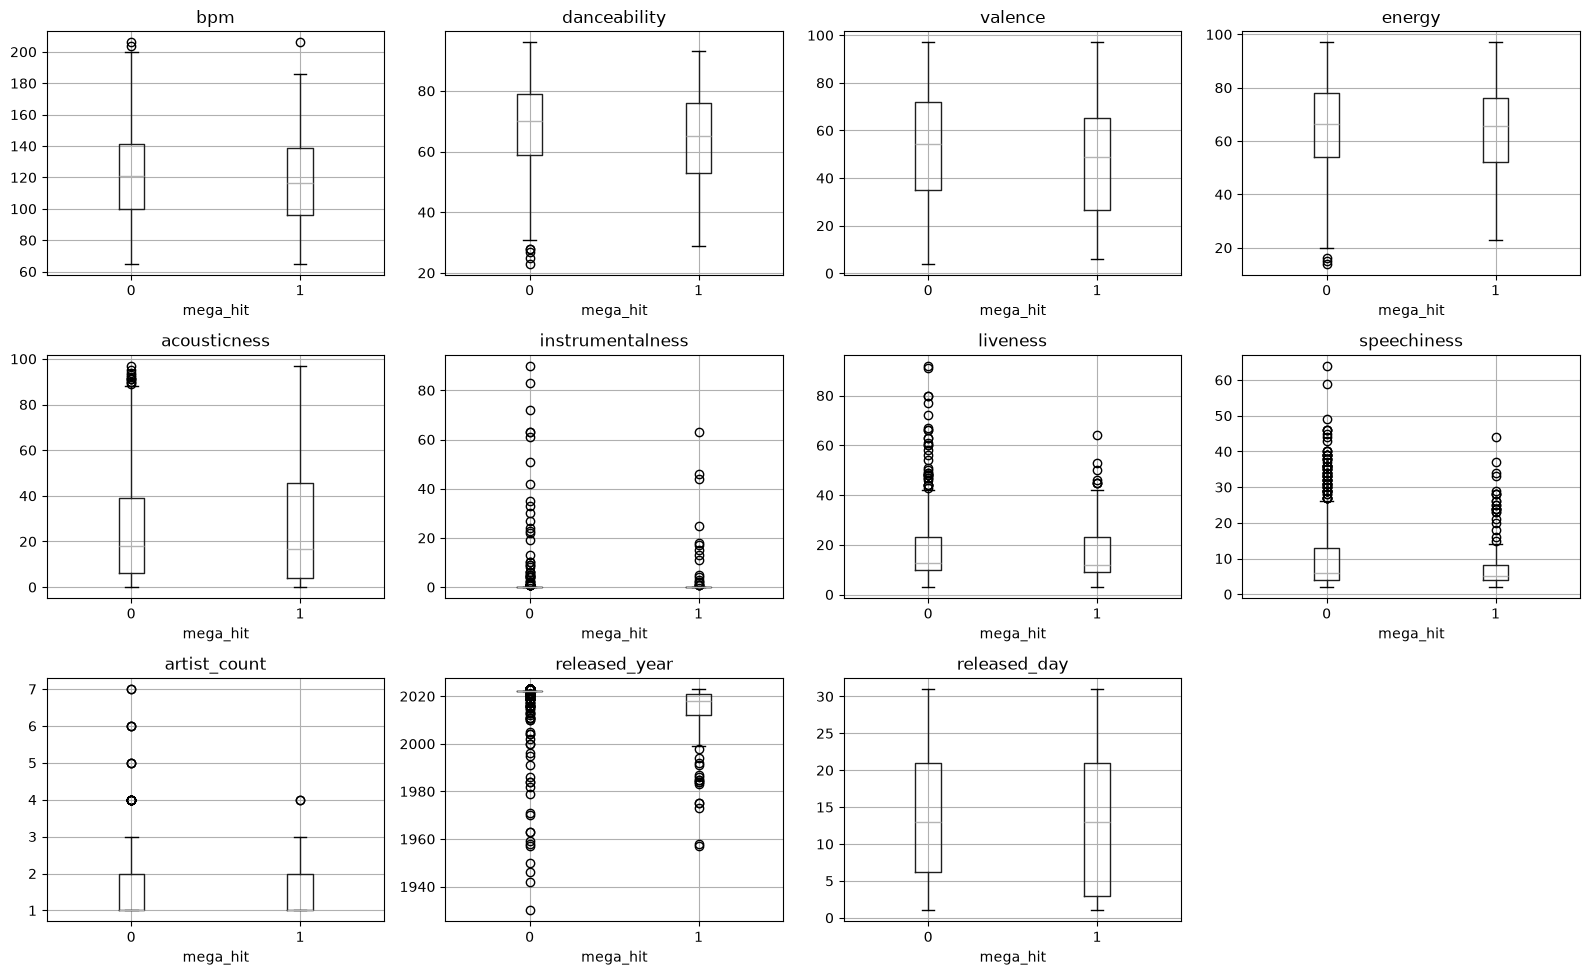

In [24]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), numerical):
    df_full_train.boxplot(column=col, by='mega_hit', ax=ax)
    ax.set_title(col)
for ax in axes.flatten()[len(numerical):]:
    ax.axis('off')
plt.suptitle('')
plt.tight_layout()
plt.show()

- For most audio features (bpm, energy, acousticness, liveness, instrumentalness) the boxes basically overlap, so the music alone doesn't separate the classes well.
- Speechiness and valence sit a little lower for mega-hits, which matches the small negative correlations from before.
- `released_year` is the one that looks different: mega-hits are spread across older years, while non-hits are bunched around 2020-2022 with a long tail of older outliers.
- `artist_count` has the same median (1) in both groups, but the non-hits include more songs with lots of artists.
- `released_day` looks identical in both groups, so it's probably safe to drop later.

In [15]:
from scipy.stats import pointbiserialr
from sklearn.metrics import roc_auc_score

rows = []
for col in numerical:
    corr, p = pointbiserialr(df_full_train['mega_hit'], df_full_train[col])
    auc = roc_auc_score(df_full_train['mega_hit'], df_full_train[col])
    rows.append({'feature': col, 'correlation': corr, 'p_value': p, 'auc': auc, 'auc_distance': abs(auc - 0.5)})

summary = pd.DataFrame(rows).set_index('feature').sort_values('auc_distance', ascending=False)
summary.round(3)

,correlation,p_value,auc,auc_distance
feature,,,,
released_year,-0.237,0.000,0.156,0.344
artist_count,-0.145,0.000,0.415,0.085
speechiness,-0.125,0.001,0.416,0.084
danceability,-0.115,0.002,0.426,0.074
valence,-0.095,0.009,0.437,0.063
bpm,-0.048,0.189,0.461,0.039
energy,-0.044,0.231,0.471,0.029
liveness,-0.042,0.248,0.471,0.029
released_day,-0.021,0.563,0.474,0.026


- `released_year` is by far the strongest. Older songs are way more likely to be mega-hits (AUC ≈ 0.84 if flipped). Probably because they've had more time to rack up streams.
- `artist_count`,`speechiness`, `danceability`, and `valence` have small negative links (r ≈ -0.1).
- `bpm`, `energy`, `liveness`, `instrumentalness`, `acousticness`, and `released_day` show basically nothing (p > 0.18).
- So the music itself is a pretty weak predictor, release timing does most of the work.

In [16]:
from scipy.stats import chi2_contingency

for c in categorical:
    table = pd.crosstab(df_full_train[c], df_full_train['mega_hit'])
    chi2, p, dof, expected = chi2_contingency(table)
    print(c, 'p-value:', round(p, 4))

key p-value: 0.4773
mode p-value: 0.7203
released_month p-value: 0.0


- `key` and `mode` show no real relationship with being a mega-hit.
- `released_month` does show one, but it might just be tangled up with release year, so I checked that next.

In [17]:
is_2023 = df_full_train['released_year'] == 2023

for name, subset in [('2023', df_full_train[is_2023]), ('before 2023', df_full_train[~is_2023])]:
    print(name)
    display(subset.groupby('released_month')['mega_hit'].agg(['mean', 'count']).round(2))

2023


,mean,count
released_month,,
1,0.11,18
2,0.00,19
3,0.00,29
4,0.00,19
5,0.00,24
6,0.00,23
7,0.00,12


before 2023


,mean,count
released_month,,
1,0.55,95
2,0.20,30
3,0.53,36
4,0.31,32
5,0.21,85
6,0.24,42
7,0.28,39
8,0.29,35
9,0.42,38


- 2023 songs are almost never mega-hits, which makes sense since they haven't had time to build up streams. This is what drags down Jan-Jul overall.
- Among older songs, the month pattern is still there: Jan and Mar are high, while Nov and Dec are low. So it's not purely a recency thing.

In [18]:
old = df_full_train[df_full_train['released_year'] < 2023]
old[old['released_month'] == 1]['released_day'].value_counts().head()

released_day
1     52
7     18
15     3
10     3
21     3
Name: count, dtype: int64

- Having 52 counts on the 1st day of the month and 95 counts in January shows that these might just be a placeholder for old-songs.
- `released_month` and `released_day` might not be good predictors, so I won't read too much into it. I'll keep `released_month` in for now and see if it helps the models.

In [25]:
year_bucket = pd.cut(
    df_full_train['released_year'],
    bins=[1900, 2015, 2019, 2021, 2022, 2023],
    labels=['<=2015', '2016-19', '2020-21', '2022', '2023']
)
df_full_train.groupby(year_bucket, observed=True)['mega_hit'].agg(['mean', 'count']).round(3)

,mean,count
released_year,,
<=2015,0.655,110
2016-19,0.683,63
2020-21,0.357,115
2022,0.092,326
2023,0.014,144


In [31]:
for c in categorical:
    df_group = df_full_train.groupby(c)['mega_hit'].agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    display(df_group.round(3))

,mean,count,diff,risk
key,,,,
A,0.161,62,-0.087,0.650
A#,0.283,46,0.035,1.139
B,0.242,66,-0.006,0.977
C#,0.278,97,0.030,1.122
D,0.258,66,0.010,1.039
D#,0.333,27,0.085,1.344
E,0.365,52,0.117,1.473
F,0.231,65,-0.017,0.930
F#,0.283,53,0.035,1.141


,mean,count,diff,risk
mode,,,,
Major,0.254,433,0.006,1.024
Minor,0.240,325,-0.008,0.968


,mean,count,diff,risk
released_month,,,,
1,0.478,113,0.230,1.927
2,0.122,49,-0.126,0.494
3,0.292,65,0.044,1.179
4,0.196,51,-0.052,0.791
5,0.165,109,-0.083,0.666
6,0.154,65,-0.094,0.620
7,0.216,51,-0.032,0.870
8,0.286,35,0.038,1.152
9,0.421,38,0.173,1.698


- The overall mega-hit rate is about 25%, so a risk above 1 means a higher chance than average.
- **Key:** E (1.47) and D# (1.34) look highest, A (0.65) and G (0.80) lowest. But the chi-square test said there's no real relationship (p = 0.48), and D# only has 27 songs, so this is probably just chance.
- **Mode:** Major (25.4%) and Minor (24.0%) are basically the same.
- **Month:** January stands out (risk 1.93, 48% mega-hits across 113 songs), and September is high too (1.70, but only 38 songs). December (0.53), February (0.49), November (0.64), and June (0.62) are low.
- Month looks real (p ≈ 0) and held up among pre-2023 songs, but some of it may be tangled up with release year. I'll keep it and let the models decide if it helps.

# One-hot encoding

# Models and tuning

# Evaluation